### Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under 20 dollars), coffee houses, carry out & take away, bar, and more expensive restaurants (20 - 50 dollars).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [277]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

## Project Overview

In this project, I looked at what factors may influence whether drivers accept coupons offered while driving.

The dataset contains 12,684 observations, with an overall coupon acceptance rate of 56.84%. I used pandas and visualizations to compare acceptance rates across different groups of drivers.

I first explored Bar coupons and then chose Coffee House coupons for my independent investigation.

One thing I noticed is that drivers who regularly visit a particular type of business are more likely to accept coupons for that business. For Coffee House coupons, traveling with friends or partners also seems to make a difference, while age showed less consistent results.

These findings suggest that businesses could improve their coupon targeting by considering customers' existing habits.

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [278]:
data = pd.read_csv('data/coupons.csv')

In [279]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

### Checking for Missing Data

Before cleaning the dataset, I used `data.isnull().sum()` to check how many missing values there were in each column.

I also calculated the percentage of missing values for each column to get a better idea of how much data was missing and help decide what to do with those values.

In [280]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

In [281]:
# Count missing values in each column
display(data.isnull().sum())

# Calculate the percentage of missing values in each column
display((data.isnull().sum() / len(data) * 100).round(2))

,0
destination,0
passanger,0
weather,0
temperature,0
time,0
coupon,0
expiration,0
gender,0
age,0
maritalStatus,0


,0
destination,0.00
passanger,0.00
weather,0.00
temperature,0.00
time,0.00
coupon,0.00
expiration,0.00
gender,0.00
age,0.00
maritalStatus,0.00


3. Decide what to do about your missing data -- drop, replace, other...

### Missing Data Observations

Most columns have no missing values. However, the `car` column is missing 99.15% of its values.

Five other columns (`Bar`, `CoffeeHouse`, `CarryAway`, `RestaurantLessThan20`, and `Restaurant20To50`) have relatively few missing values, ranging from 0.84% to 1.71%.

Since these columns describe how frequently customers visit different establishments, they may be useful when investigating coupon acceptance.

I decided to remove the `car` column and retain the other five columns, handling their missing values as needed during the analysis.

In [282]:
# Remove the car column because 99.15% of its values are missing
data = data.drop(columns=['car'])

# Verify the dimensions of the cleaned dataset
data.shape


(12684, 25)

4. What proportion of the total observations chose to accept the coupon?



### Overall Coupon Acceptance Rate

Next, I want to determine what proportion of drivers accepted the coupon. The `Y` column indicates whether a driver accepted (`1`) or rejected (`0`) the coupon.

Since `Y` contains binary values, I can calculate the overall acceptance rate by taking its mean. This will give me a baseline to compare against acceptance rates for different coupon types and customer groups later in the analysis.

In [283]:
# Calculate the proportion of drivers who accepted a coupon
acceptance_rate = data['Y'].mean()

acceptance_rate

print(f"Overall coupon acceptance rate: {acceptance_rate:.2%}")

Overall coupon acceptance rate: 56.84%


In [284]:
# For practice with pandas, let's also examine the distribution of accepted and rejected coupons:
data['Y'].value_counts(normalize=True)

,proportion
Y,
1,0.568433
0,0.431567


### Observation

The overall coupon acceptance rate was 56.84%, while 43.16% were rejected. Slightly more than half of the coupons were accepted.

I'll use this as a baseline when looking at different coupon types to see which customers are more likely to accept them.

Next, I'll look at the different coupon types in the dataset. I'll use a bar plot to see how many observations there are for each type and compare how frequently they were offered.

5. Use a bar plot to visualize the `coupon` column.

### Distribution of Coupon Types

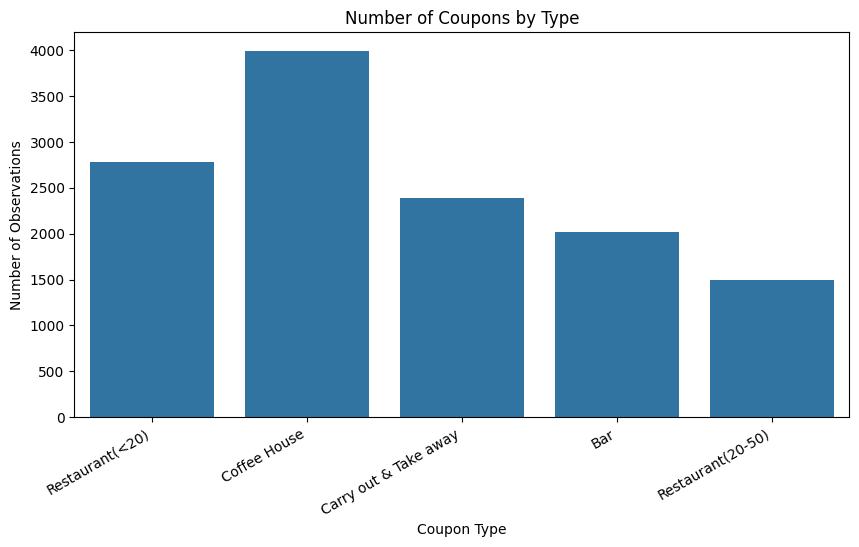

In [285]:
# Compare the number of observations for each coupon type
plt.figure(figsize=(10, 5))

sns.countplot(data=data, x='coupon')

plt.title('Number of Coupons by Type')
plt.xlabel('Coupon Type')
plt.ylabel('Number of Observations')
plt.xticks(rotation=30, ha='right')

plt.show()

Coffee House coupons had the most observations (about 4,000), followed by restaurants under $20 (about 2,800).

Restaurants between $20 and $50 had the fewest (about 1,500).

Since the number of coupons offered varies by type, I'll keep that in mind when comparing acceptance rates later. Next, I'll look at the temperature distribution to better understand the driving conditions in the dataset.

6. Use a histogram to visualize the temperature column.

### Distribution of Temperatures

,count
temperature,
30,2316
55,3840
80,6528


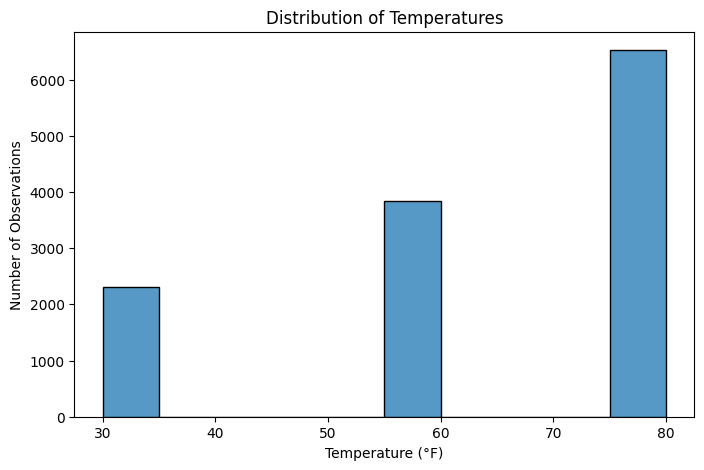

In [286]:
# Count observations at each temperature
display(data['temperature'].value_counts().sort_index())

# Visualize the distribution of temperatures
plt.figure(figsize=(8, 5))

sns.histplot(data=data, x='temperature', bins=10)

plt.title('Distribution of Temperatures')
plt.xlabel('Temperature (°F)')
plt.ylabel('Number of Observations')

plt.show()



The highest temperature had almost twice as many observations as the next most common temperature. This suggests that more of the driving scenarios in the dataset occurred under warmer conditions.

### Coupon Acceptance Rate by Temperature

In [287]:
# Calculate the coupon acceptance rate at each temperature
(data.groupby('temperature')['Y'].mean() * 100).round(2)

,Y
temperature,
30,53.11
55,53.67
80,60.03


Coupon acceptance rates seem to increase with warmer temperatures, with the highest acceptance rate of about 60% at 80°F. This suggests a possible relationship between temperature and coupon acceptance, although other factors may also play a role.

Next, I'll focus on bar coupons to see how acceptance rates differ among drivers. I'll look at factors such as how often they visit bars, their age, and who they're traveling with.

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


### Bar Coupon Analysis

In [288]:
# Filter the dataset to include only Bar coupons
bar_data = data[data['coupon'] == 'Bar']

# Check the number of observations and columns
bar_data.shape

(2017, 25)

In [289]:
# Check restaurant visit frequency among Bar coupon recipients
print(bar_data['RestaurantLessThan20'].value_counts(dropna=False))
print()

# Check income distribution among Bar coupon recipients
print(bar_data['income'].value_counts(dropna=False))

RestaurantLessThan20
1~3      878
4~8      568
less1    325
gt8      186
never     37
NaN       23
Name: count, dtype: int64

income
$25000 - $37499     318
$100000 or More     291
$12500 - $24999     288
$37500 - $49999     267
$50000 - $62499     262
Less than $12500    165
$75000 - $87499     151
$87500 - $99999     145
$62500 - $74999     130
Name: count, dtype: int64


2. What proportion of bar coupons were accepted?


In [290]:
# Calculate the overall acceptance rate for Bar coupons
bar_acceptance_rate = bar_data['Y'].mean()

print(f"Bar coupon acceptance rate: {bar_acceptance_rate:.2%}")


Bar coupon acceptance rate: 41.00%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


### Bar Coupon Acceptance by Visit Frequency

In [291]:
# Check how frequently drivers visit bars
display(bar_data['Bar'].value_counts(dropna=False))

# Separate drivers based on how often they visit bars
bar_3_or_less = bar_data[
    bar_data['Bar'].isin(['never', 'less1', '1~3'])
]

bar_more_than_3 = bar_data[
    bar_data['Bar'].isin(['4~8', 'gt8'])
]

# Calculate acceptance rates for both groups
rate_3_or_less = bar_3_or_less['Y'].mean()
rate_more_than_3 = bar_more_than_3['Y'].mean()

print(f"Drivers visiting bars 3 or fewer times per month: {len(bar_3_or_less):,} drivers, {rate_3_or_less:.2%} accepted the coupon")
print(f"Drivers visiting bars more than 3 times per month: {len(bar_more_than_3):,} drivers, {rate_more_than_3:.2%} accepted the coupon")

,count
Bar,
never,830
less1,570
1~3,397
4~8,150
gt8,49
NaN,21


Drivers visiting bars 3 or fewer times per month: 1,797 drivers, 37.06% accepted the coupon
Drivers visiting bars more than 3 times per month: 199 drivers, 76.88% accepted the coupon


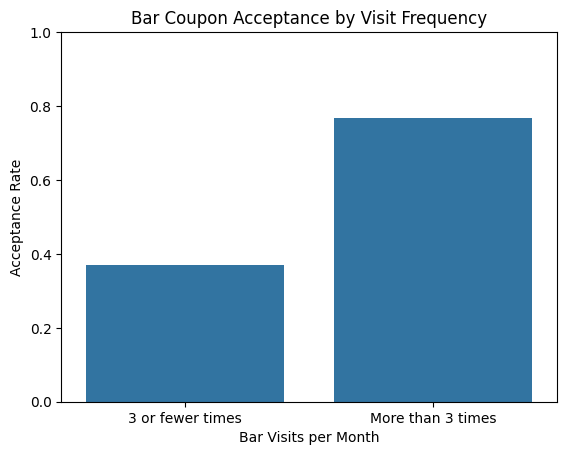

In [292]:
# Create a DataFrame to compare the two groups
bar_comparison = pd.DataFrame({
    'Visit Frequency': ['3 or fewer times', 'More than 3 times'],
    'Acceptance Rate': [rate_3_or_less, rate_more_than_3]
})

# Visualize acceptance rates by bar visit frequency
sns.barplot(
    data=bar_comparison,
    x='Visit Frequency',
    y='Acceptance Rate',
    errorbar=None
)

plt.title('Bar Coupon Acceptance by Visit Frequency')
plt.xlabel('Bar Visits per Month')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)
plt.show()

Drivers who visited bars more than three times a month had a much higher coupon acceptance rate (76.88%) compared with those who visited three or fewer times (37.06%).

However, the group visiting bars more frequently was much smaller (199 drivers compared with 1,797). This is worth keeping in mind when comparing the results.

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


Next, I'll compare drivers over 25 who visit bars more than once a month with the other drivers who received bar coupons. I want to see whether age and bar-visiting frequency together make a difference in coupon acceptance.

### Bar Coupon Acceptance by Age and Visit Frequency

In [293]:
# Select drivers over 25 who visit bars at least once a month
bar_over25_frequent = bar_data[
    (bar_data['age'].isin(['26', '31', '36', '41', '46', '50plus'])) &
    (bar_data['Bar'].isin(['1~3', '4~8', 'gt8']))
]

# Select all other drivers who do not meet both conditions
# Use ~ (NOT) to select everyone who doesn't meet both conditions.
bar_others = bar_data[
    ~bar_data.index.isin(bar_over25_frequent.index)
]

# Calculate acceptance rates for both groups
rate_over25_frequent = bar_over25_frequent['Y'].mean()
rate_others = bar_others['Y'].mean()

# Display acceptance rates and group sizes
print(f"Drivers over 25 visiting bars at least once a month: {rate_over25_frequent:.2%}")
print(f"All other drivers: {rate_others:.2%}")

print(f"Drivers over 25 visiting bars at least once a month: {len(bar_over25_frequent)}")
print(f"All other drivers: {len(bar_others)}")

Drivers over 25 visiting bars at least once a month: 69.52%
All other drivers: 33.50%
Drivers over 25 visiting bars at least once a month: 420
All other drivers: 1597


Drivers over 25 who visit bars at least once a month had a much higher bar coupon acceptance rate (69.52%) compared with all other drivers (33.50%). This is a difference of about 36 percentage points.

The results suggest that age and bar-visiting frequency together may help identify drivers who are more likely to accept bar coupons.

One limitation is that the dataset groups bar visits into categories, including 1~3 visits per month. Since we cannot distinguish drivers who visit exactly once from those who visit more than once, I used at least once a month as an approximation for this comparison.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


### Bar Coupon Acceptance by Visit Frequency, Passenger, and Occupation


In [294]:
# Select drivers who meet all three conditions
bar_group = bar_data[
    (bar_data['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_data['passanger'].isin(['Friend(s)', 'Partner'])) &
    (bar_data['occupation'] != 'Farming Fishing & Forestry')
]

# Display the group size and Bar coupon acceptance rate
print(f"Number of drivers meeting all three conditions: {len(bar_group)}")
print(f"Bar coupon acceptance rate: {bar_group['Y'].mean():.2%}")

Number of drivers meeting all three conditions: 195
Bar coupon acceptance rate: 71.79%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [295]:
# Select drivers who meet all three conditions
bar_q6_group1 = bar_data[
    (bar_data['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_data['passanger'].isin(['Friend(s)', 'Partner'])) &
    (bar_data['maritalStatus'] != 'Widowed')
]

# Display the group size and coupon acceptance rate
print(f"Drivers visiting bars at least once a month, traveling with friends or a partner, and not widowed: {len(bar_q6_group1)}")
print(f"Bar coupon acceptance rate for these drivers: {bar_q6_group1['Y'].mean():.2%}")



Drivers visiting bars at least once a month, traveling with friends or a partner, and not widowed: 195
Bar coupon acceptance rate for these drivers: 71.79%


In [296]:
# Select drivers under 30 who visit bars at least once a month
bar_q6_group2 = bar_data[
    (bar_data['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (bar_data['age'].isin(['below21', '21', '26']))
]

# Display the group size and coupon acceptance rate
print(f"Number of drivers under 30 who visit bars at least once a month: {len(bar_q6_group2)}")
print(f"Bar coupon acceptance rate for these drivers: {bar_q6_group2['Y'].mean():.2%}")

Number of drivers under 30 who visit bars at least once a month: 345
Bar coupon acceptance rate for these drivers: 72.17%


In [297]:
# Check restaurant visit frequency and income categories
print(bar_data['RestaurantLessThan20'].value_counts(dropna=False))
print()
print(bar_data['income'].value_counts(dropna=False))

# Select drivers who visit inexpensive restaurants at least 4 times
# per month and earn less than $50,000 annually
bar_q6_group3 = bar_data[
    (bar_data['RestaurantLessThan20'].isin(['4~8', 'gt8'])) &
    (bar_data['income'].isin([
        'Less than $12500',
        '$12500 - $24999',
        '$25000 - $37499',
        '$37500 - $49999'
    ]))
]

# Display the group size and Bar coupon acceptance rate
print()
print(f"Number of drivers who visit restaurants under $20 at least 4 times a month and earn less than $50K: {len(bar_q6_group3)}")
print(f"Bar coupon acceptance rate for these drivers: {bar_q6_group3['Y'].mean():.2%}")

RestaurantLessThan20
1~3      878
4~8      568
less1    325
gt8      186
never     37
NaN       23
Name: count, dtype: int64

income
$25000 - $37499     318
$100000 or More     291
$12500 - $24999     288
$37500 - $49999     267
$50000 - $62499     262
Less than $12500    165
$75000 - $87499     151
$87500 - $99999     145
$62500 - $74999     130
Name: count, dtype: int64

Number of drivers who visit restaurants under $20 at least 4 times a month and earn less than $50K: 344
Bar coupon acceptance rate for these drivers: 45.35%


I compared the bar coupon acceptance rates across three groups of drivers.

Drivers under 30 who visit bars at least once a month had the highest acceptance rate (72.17%), followed closely by drivers who visit bars at least once a month, have non-child passengers, and are not widowed (71.79%).

Drivers who visit inexpensive restaurants at least four times a month and earn less than $50,000 had a lower acceptance rate (45.35%).

These results suggest that bar-visiting habits may be more useful than restaurant-visiting frequency and income for identifying drivers likely to accept bar coupons.

One limitation is that the dataset uses visit-frequency ranges (1~3 and 4~8), so I included drivers who visit bars at least once a month and inexpensive restaurants at least four times a month as approximations for the assignment's thresholds.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on these results, I think drivers who regularly visit bars are more likely to accept bar coupons than those who rarely visit bars.

Bar-visiting frequency seems to be a stronger indicator of acceptance than age or income alone. Drivers who already visit bars may find these coupons more relevant to their usual activities.

My hypothesis is that targeting drivers based on their existing bar-visiting habits could lead to higher coupon acceptance rates.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

**Coffee House Coupons**

For this part of the assignment, I decided to explore Coffee House coupons since they were the most frequently offered coupon type in the dataset.

I want to understand what characteristics are associated with drivers accepting these coupons. I'll look at factors such as how often they visit coffee shops, their age, who they're traveling with, and the time of day.

My goal is to identify patterns that could help determine which drivers are more likely to accept Coffee House coupons.

### Coffee House Coupon Analysis

In [298]:
# Select drivers who received Coffee House coupons
coffee_data = data[data['coupon'] == 'Coffee House']

# Display the number of coupons and overall acceptance rate
print(f"Number of Coffee House coupons offered: {len(coffee_data):,}")
print(f"Coffee House coupon acceptance rate: {coffee_data['Y'].mean():.2%}")

Number of Coffee House coupons offered: 3,996
Coffee House coupon acceptance rate: 49.92%


In [299]:
# Count drivers in each Coffee House visit-frequency category, including missing values
coffee_data['CoffeeHouse'].value_counts(dropna=False)

,count
CoffeeHouse,
less1,1075
1~3,1042
never,927
4~8,538
gt8,342
NaN,72


**Coffee House Visiting Frequency and Coupon Acceptance**

Of the 3,996 Coffee House coupons offered, 49.92% were accepted, which is lower than the overall coupon acceptance rate of 56.84%.

Next, I'll look at whether drivers who visit coffee shops more frequently are also more likely to accept Coffee House coupons. I'll compare acceptance rates across the different visiting-frequency groups.

In [300]:
# Calculate the number of observations and acceptance rate for each visit-frequency group
coffee_acceptance_by_visits = (
    coffee_data.groupby('CoffeeHouse')['Y']
    .agg(['count', 'mean'])
)

# Convert acceptance rates from proportions to percentages
coffee_acceptance_by_visits['mean'] = (
    coffee_acceptance_by_visits['mean'] * 100
)

coffee_acceptance_by_visits

,count,mean
CoffeeHouse,,
1~3,1042,64.779271
4~8,538,68.587361
gt8,342,65.789474
less1,1075,48.186047
never,927,18.878101


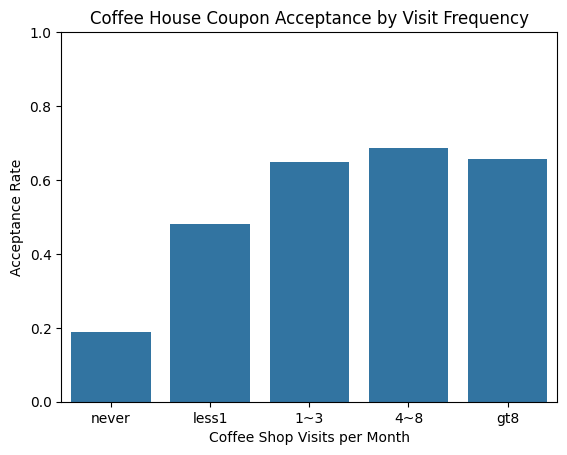

In [301]:
# Arrange visit-frequency categories from least to most frequent
visit_order = ['never', 'less1', '1~3', '4~8', 'gt8']

# Compare Coffee House coupon acceptance rates by visit frequency
sns.barplot(
    data=coffee_data,
    x='CoffeeHouse',
    y='Y',
    order=visit_order,
    errorbar=None
)

plt.title('Coffee House Coupon Acceptance by Visit Frequency')
plt.xlabel('Coffee Shop Visits per Month')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)
plt.show()

Coffee House coupon acceptance appears to be associated with how often drivers visit coffee shops. Drivers who never visit coffee shops had the lowest acceptance rate (18.88%), while those who visit 4–8 times a month had the highest (68.59%).

Acceptance generally increased with visiting frequency, although it dropped slightly for drivers visiting more than eight times a month. This suggests that drivers who already visit coffee shops regularly may be better targets for Coffee House coupons.

### Coffee House Coupon Acceptance by Age

Next, I'll look at whether age is associated with Coffee House coupon acceptance. I'll compare acceptance rates across different age groups to see if any patterns stand out.

In [302]:
# Calculate the number of observations and acceptance rate for each age group
coffee_acceptance_by_age = (
    coffee_data.groupby('age')['Y']
    .agg(['count', 'mean'])
)

# Convert acceptance rates from proportions to percentages
coffee_acceptance_by_age['mean'] = (
    coffee_acceptance_by_age['mean'] * 100
)

coffee_acceptance_by_age

,count,mean
age,,
21,883,52.434881
26,843,51.482800
31,623,47.672552
36,402,46.766169
41,325,50.153846
46,220,51.363636
50plus,545,42.018349
below21,155,69.677419


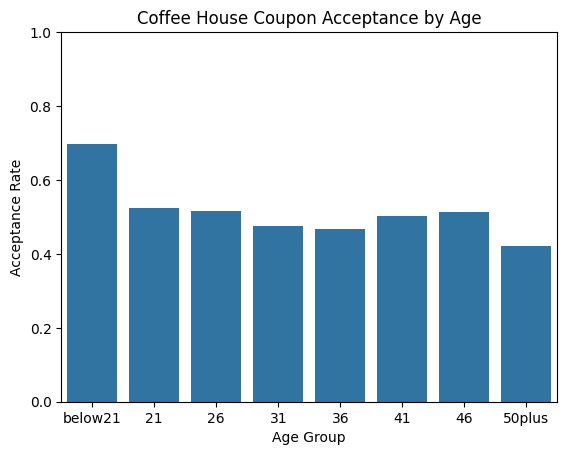

In [303]:
# Arrange age categories from youngest to oldest
age_order = ['below21', '21', '26', '31', '36', '41', '46', '50plus']

# Compare Coffee House coupon acceptance rates across age groups
sns.barplot(
    data=coffee_data,
    x='age',
    y='Y',
    order=age_order,
    errorbar=None
)

plt.title('Coffee House Coupon Acceptance by Age')
plt.xlabel('Age Group')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)
plt.show()

Drivers under 21 had the highest Coffee House coupon acceptance rate at 69.68%, while those 50 and older had the lowest at 42.02%.

However, most of the other age groups had similar acceptance rates, ranging from about 47% to 52%. This suggests that age alone may not be a strong indicator of coupon acceptance, although younger drivers stood out. There were also only 155 drivers under 21, so I would be cautious about drawing conclusions from that group.

**Coffee House Coupon Acceptance by Passenger Type**

In [304]:
# Calculate the number of observations and acceptance rate for each passenger group
coffee_acceptance_by_passenger = (
    coffee_data.groupby('passanger')['Y']
    .agg(['count', 'mean'])
)

# Convert acceptance rates from proportions to percentages
coffee_acceptance_by_passenger['mean'] = (
    coffee_acceptance_by_passenger['mean'] * 100
)

coffee_acceptance_by_passenger

,count,mean
passanger,,
Alone,2256,43.794326
Friend(s),1228,59.690554
Kid(s),207,48.309179
Partner,305,57.049180


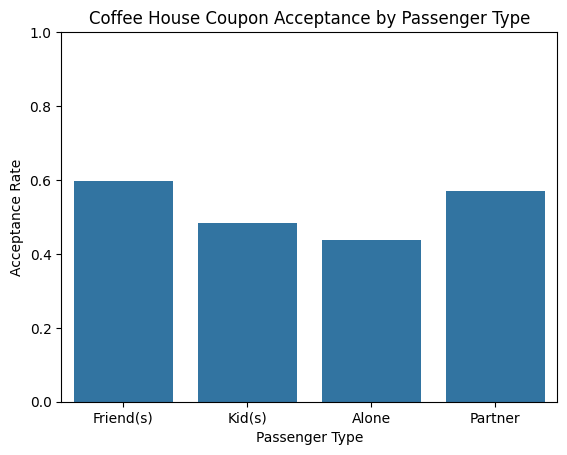

In [305]:
# Compare Coffee House coupon acceptance rates by passenger type
sns.barplot(
    data=coffee_data,
    x='passanger',
    y='Y',
    errorbar=None
)

plt.title('Coffee House Coupon Acceptance by Passenger Type')
plt.xlabel('Passenger Type')
plt.ylabel('Acceptance Rate')
plt.ylim(0, 1)
plt.show()

Drivers traveling with friends had the highest Coffee House coupon acceptance rate at 59.69%, followed by those traveling with partners at 57.05%. Drivers traveling alone had the lowest rate at 43.79%, even though they received the most coupons.

This suggests that drivers traveling with friends or partners may be more likely to accept Coffee House coupons than those traveling alone.

### Findings and Recommendations

From my analysis, how often drivers visit coffee shops seems to have the strongest relationship with Coffee House coupon acceptance. Drivers who never visit coffee shops had an acceptance rate of only 18.88%, compared to 68.59% for those who visit 4–8 times a month.

I also noticed that drivers traveling with friends or partners were more likely to accept Coffee House coupons than those traveling alone. Age showed some differences, but most age groups had similar acceptance rates.

Based on these findings, I would recommend targeting Coffee House coupons toward drivers who already visit coffee shops regularly, especially when traveling with friends or partners. This could help improve coupon acceptance rather than offering coupons to everyone equally.

As a next step, I would look at how visit frequency interacts with other factors, such as time of day, distance to the business, and who is traveling with the driver. I would also want to test whether targeting coupons based on these patterns actually improves acceptance rates.

These findings show associations in the data, but they don't necessarily mean these factors cause drivers to accept coupons.

## Overall Conclusions

From this analysis, I noticed that coupon acceptance varies depending on the type of coupon and the driver's habits.

For Bar coupons, drivers who visit bars more often were more likely to accept them. I saw a similar pattern with Coffee House coupons, where drivers who regularly visit coffee shops had higher acceptance rates.

I also found that drivers traveling with friends or partners were more likely to accept Coffee House coupons than those traveling alone. Age made some difference, but most age groups had similar acceptance rates.

Based on these findings, I think businesses could improve coupon acceptance by targeting drivers based on their habits rather than offering coupons to everyone. How often someone visits a particular type of business seems to be a useful factor to consider.

Of course, these are patterns I observed in the data and don't necessarily mean one factor causes another.